Dataset shape: (2075259, 9)
Training data: (1639424, 7)
Testing data: (409856, 7)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 3)                   │              27 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 8)                   │              32 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 7)                   │             119 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 586 (2.29 KB)

 Trainable params: 586 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - loss: 0.1542 - mae: 0.2096 - val_loss: 0.0659 - val_mae: 0.1297
Epoch 2/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.0428 - mae: 0.0981 - val_loss: 0.0488 - val_mae: 0.1029
Epoch 3/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.0357 - mae: 0.0845 - val_loss: 0.0420 - val_mae: 0.0924
Epoch 4/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.0310 - mae: 0.0770 - val_loss: 0.0385 - val_mae: 0.0859
Epoch 5/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 0.0281 - mae: 0.0714 - val_loss: 0.0368 - val_mae: 0.0819
Epoch 6/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.0263 - mae: 0.0681 - val_loss: 0.0346 - val_mae: 0.0796
Epoch 7/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.0252 - mae: 0.0662 - val_loss: 0.0334 - val_mae: 0.0766
Epoch 8/30
2882/2882 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.0244 - mae: 0.0646 - val_loss: 0.0329 - val_mae: 0.0759
Epoch 9/30
2882/2882 ━━━━━━━━━━━━

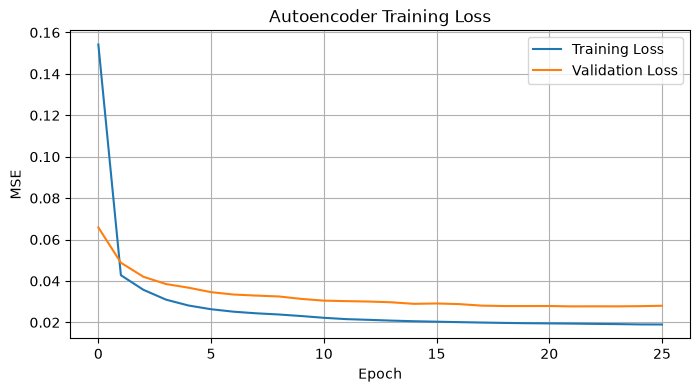

Mean training error: 0.02047
Anomaly threshold: 0.42967
Detected anomalies: 3316
Total test samples: 409856
Anomaly percentage: 0.81 %


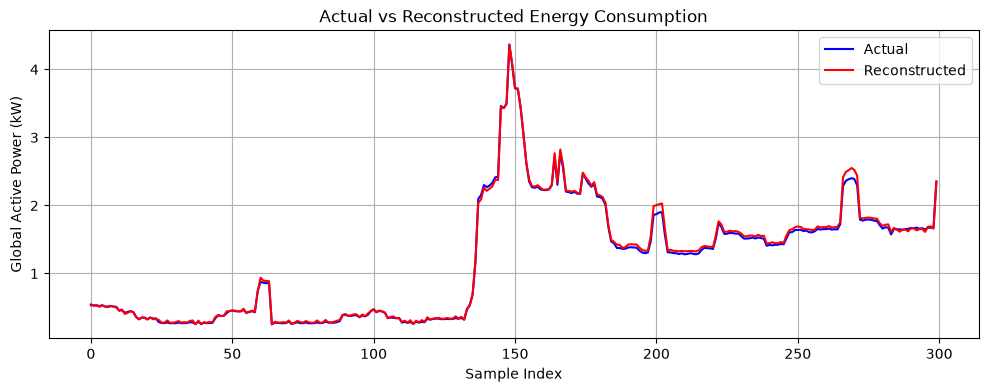

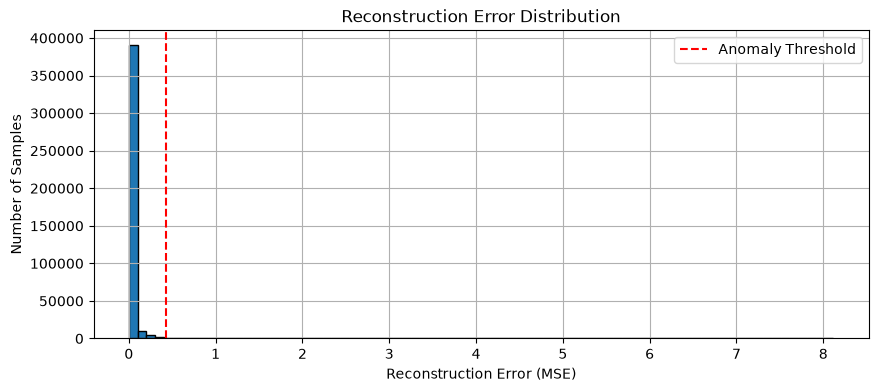


Top 10 unusual consumption patterns:
                     Reconstruction Error  Anomaly
Timestamp                                         
2010-09-05 15:14:00              8.116392     True
2010-09-05 15:19:00              5.904987     True
2010-09-05 15:13:00              5.889744     True
2010-03-08 12:27:00              4.469301     True
2010-03-08 12:28:00              4.429861     True
2010-10-24 14:37:00              4.284417     True
2010-11-11 15:39:00              4.269251     True
2010-02-13 12:29:00              4.113838     True
2010-10-24 14:40:00              4.108666     True
2010-06-09 13:54:00              3.781338     True


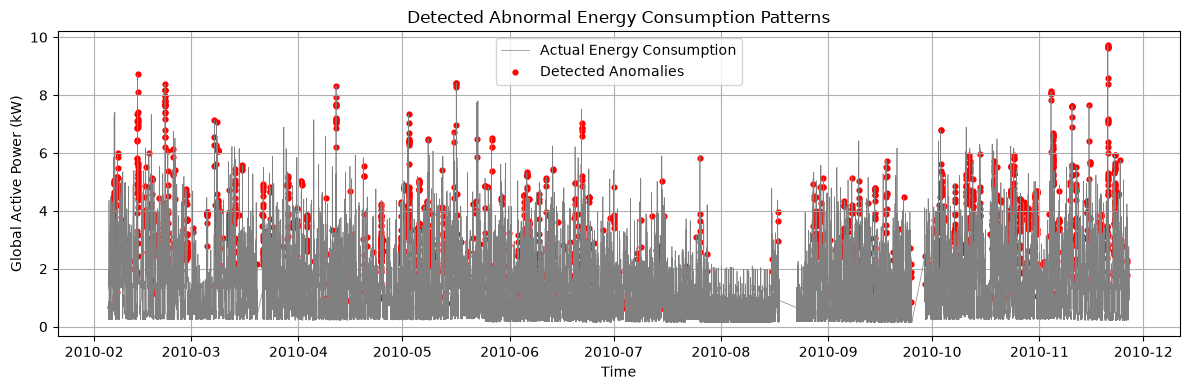

In [5]:

# a. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# b. Load the energy consumption dataset
df = pd.read_csv(
    'household_power_consumption.txt',
    sep=';',
    na_values='?',
    low_memory=False
)

print("Dataset shape:", df.shape)

# c. Data preprocessing

# Combine Date and Time into a datetime index
df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S'
)

df = df.drop(columns=['Date', 'Time'])
df = df.set_index('Datetime')

# Convert columns into numerical values and remove missing rows
df = df.apply(pd.to_numeric, errors='coerce')
df = df.dropna()
df = df.sort_index()

# Select relevant numerical features
features = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

X = df[features].values.astype('float32')

# Split chronologically: 80% training and 20% testing
split = int(0.8 * len(X))

X_train_raw = X[:split]
X_test_raw = X[split:]

# Normalize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype('float32')
X_test = scaler.transform(X_test_raw).astype('float32')

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# d. Encoder and e. Decoder
input_dim = X_train.shape[1]

autoencoder = tf.keras.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder: compress the input into 3 values
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(3, activation='relu'),

    # Decoder: reconstruct the original input
    layers.Dense(8, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(input_dim, activation='linear')
])

autoencoder.summary()

# f. Compile the autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train the autoencoder
history = autoencoder.fit(
    X_train, X_train,
    epochs=30,
    batch_size=512,
    validation_split=0.1,
    shuffle=True,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# Display training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

# g. Calculate reconstruction errors on training data
train_recon = autoencoder.predict(X_train, verbose=0)
train_loss = np.mean((X_train - train_recon) ** 2, axis=1)

# Set threshold using 99th percentile of training errors
threshold = np.percentile(train_loss, 99)

print("Mean training error:", round(train_loss.mean(), 5))
print("Anomaly threshold:", round(threshold, 5))

# Calculate reconstruction errors on test data
test_recon = autoencoder.predict(X_test, verbose=0)
test_loss = np.mean((X_test - test_recon) ** 2, axis=1)

# Identify unusual consumption patterns
flags = test_loss > threshold

print("Detected anomalies:", flags.sum())
print("Total test samples:", len(flags))
print("Anomaly percentage:", round(flags.mean() * 100, 2), "%")

# h. Display actual and reconstructed energy consumption
start, end = 0, 300

# Convert values back to their original scale
window_actual = scaler.inverse_transform(X_test[start:end])
window_recon = scaler.inverse_transform(test_recon[start:end])

col = features.index('Global_active_power')

plt.figure(figsize=(12, 4))
plt.plot(window_actual[:, col], color='blue', label='Actual')
plt.plot(window_recon[:, col], color='red', label='Reconstructed')
plt.title('Actual vs Reconstructed Energy Consumption')
plt.xlabel('Sample Index')
plt.ylabel('Global Active Power (kW)')
plt.legend()
plt.grid(True)
plt.show()

# Plot reconstruction error distribution
plt.figure(figsize=(10, 4))
plt.hist(test_loss, bins=80, edgecolor='black')
plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Number of Samples')
plt.title('Reconstruction Error Distribution')
plt.legend()
plt.grid(True)
plt.show()

# Display the top 10 unusual samples
test_times = df.index[split:]

anomaly_df = pd.DataFrame({
    'Timestamp': test_times,
    'Reconstruction Error': test_loss,
    'Anomaly': flags
})

anomaly_df = anomaly_df.set_index('Timestamp')

print("\nTop 10 unusual consumption patterns:")
print(anomaly_df.sort_values(
    'Reconstruction Error',
    ascending=False
).head(10))

# Plot detected abnormal consumption patterns
plt.figure(figsize=(12, 4))

plt.plot(
    test_times,
    X_test_raw[:, col],
    color='gray',
    linewidth=0.5,
    label='Actual Energy Consumption'
)

plt.scatter(
    test_times[flags],
    X_test_raw[flags, col],
    color='red',
    s=12,
    label='Detected Anomalies'
)

plt.title('Detected Abnormal Energy Consumption Patterns')
plt.xlabel('Time')
plt.ylabel('Global Active Power (kW)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


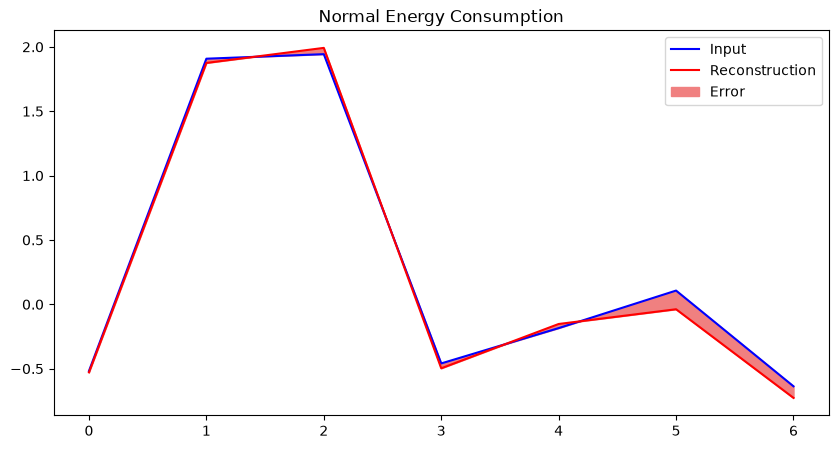

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


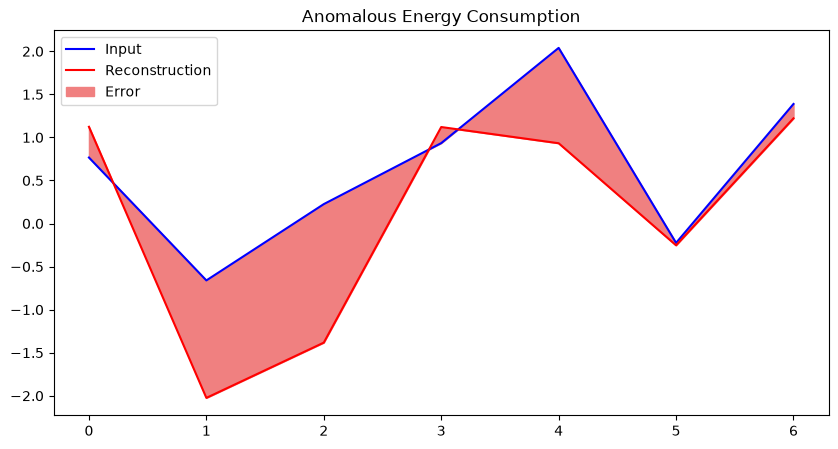

In [7]:
# Separate normal and anomalous test samples
normal_test_data = X_test[~anomalies]
anomalous_test_data = X_test[anomalies]

# Plot normal sample and its reconstruction
normal_reconstructed = autoencoder.predict(normal_test_data[:1])

plt.figure(figsize=(10, 5))
plt.plot(normal_test_data[0], 'b', label='Input')
plt.plot(normal_reconstructed[0], 'r', label='Reconstruction')
plt.fill_between(
    np.arange(len(normal_test_data[0])),
    normal_reconstructed[0],
    normal_test_data[0],
    color='lightcoral',
    label='Error'
)
plt.title('Normal Energy Consumption')
plt.legend()
plt.show()

# Plot anomalous sample and its reconstruction
anomalous_reconstructed = autoencoder.predict(anomalous_test_data[:1])

plt.figure(figsize=(10, 5))
plt.plot(anomalous_test_data[0], 'b', label='Input')
plt.plot(anomalous_reconstructed[0], 'r', label='Reconstruction')
plt.fill_between(
    np.arange(len(anomalous_test_data[0])),
    anomalous_reconstructed[0],
    anomalous_test_data[0],
    color='lightcoral',
    label='Error'
)
plt.title('Anomalous Energy Consumption')
plt.legend()
plt.show()